
=== Quantum Circuit (Before Measurement) ===


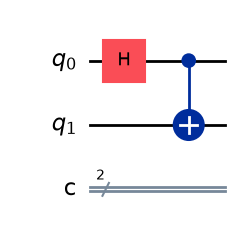


=== Statevector ===
Statevector([0.70710678+0.j, 0.        +0.j, 0.        +0.j,
             0.70710678+0.j],
            dims=(2, 2))

=== Bloch Sphere Representation ===


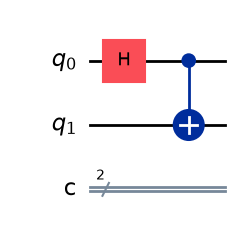

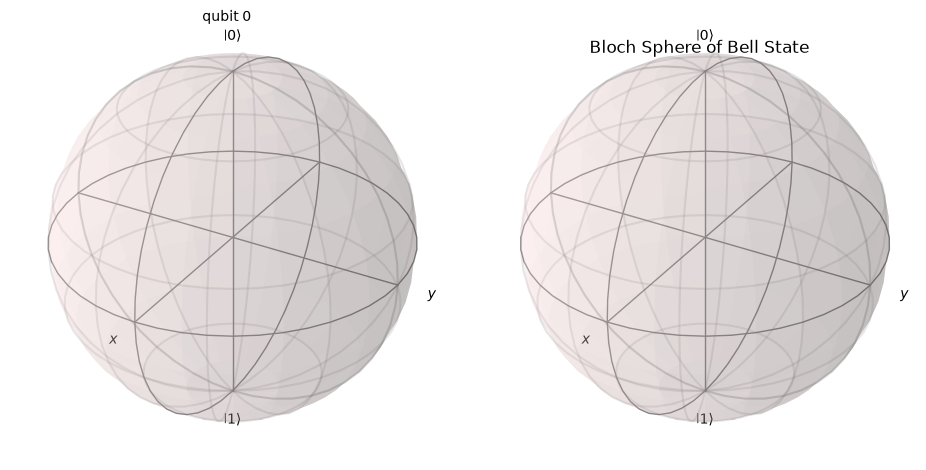


=== Q-Sphere Representation ===


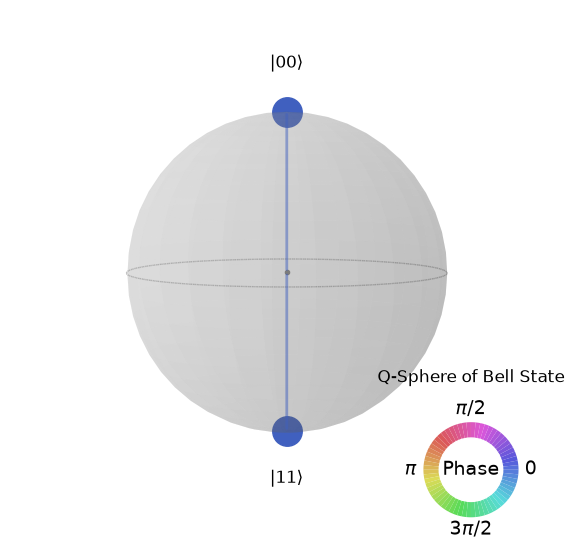


=== Quantum Circuit (With Measurement) ===


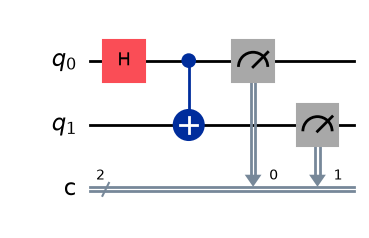


=== Measurement Results ===
{'00': 506, '11': 518}


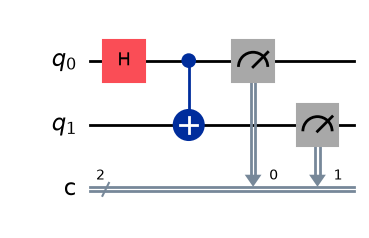

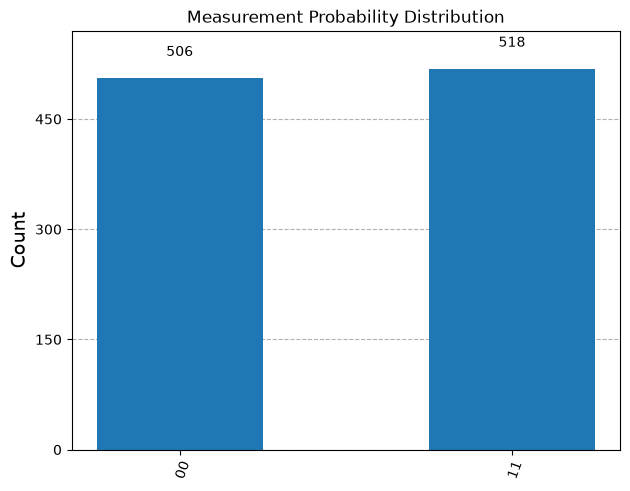

In [1]:
# ======================================================
# Qiskit Teaching Example: 2-Qubit Bell State
# Superposition + Entanglement + Measurement
# ======================================================

# Enable inline plotting for Jupyter Notebook
%matplotlib inline

from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.quantum_info import Statevector
from qiskit.visualization import (
    plot_histogram,
    plot_bloch_multivector,
    plot_state_qsphere
)
from matplotlib import pyplot as plt
from IPython.display import display

# ------------------------------------------------------
# 1️⃣ Create 2-Qubit Circuit
# ------------------------------------------------------

qc = QuantumCircuit(2, 2)

# Put qubit 0 into superposition
qc.h(0)

# Entangle qubit 0 and qubit 1
qc.cx(0, 1)

print("\n=== Quantum Circuit (Before Measurement) ===")
display(qc.draw("mpl"))

# ------------------------------------------------------
# 2️⃣ Statevector BEFORE Measurement
# ------------------------------------------------------

state = Statevector.from_instruction(qc)

print("\n=== Statevector ===")
print(state)

# ------------------------------------------------------
# 3️⃣ Bloch Sphere Visualization
# ------------------------------------------------------

print("\n=== Bloch Sphere Representation ===")
plot_bloch_multivector(state)
plt.title("Bloch Sphere of Bell State")
plt.show()

# ------------------------------------------------------
# 4️⃣ Q-Sphere Visualization
# ------------------------------------------------------

print("\n=== Q-Sphere Representation ===")
plot_state_qsphere(state)
plt.title("Q-Sphere of Bell State")
plt.show()

# ------------------------------------------------------
# 5️⃣ Add Measurement
# ------------------------------------------------------

qc.measure([0,1], [0,1])

print("\n=== Quantum Circuit (With Measurement) ===")
display(qc.draw("mpl"))

# ------------------------------------------------------
# 6️⃣ Simulation
# ------------------------------------------------------

simulator = AerSimulator()
job = simulator.run(qc, shots=1024)
result = job.result()
counts = result.get_counts()

print("\n=== Measurement Results ===")
print(counts)

# ------------------------------------------------------
# 7️⃣ Histogram
# ------------------------------------------------------

plot_histogram(counts)
plt.title("Measurement Probability Distribution")
plt.show()
